# IR 2 — Pre-optimized functional-group classifier

Run this notebook after IR 1, without editing it. It reads the fixed training, validation, and test Parquet files plus their data manifest. This static pipeline makes it easy to see the effect of a participant's carpentry choices while retaining good experimental boundaries: training-only feature scaling and class weighting, validation-only early stopping and threshold tuning, then one untouched test evaluation.

The model is a regularized feed-forward neural-network head for 500-point IR spectra: ReLU layers, batch normalization, dropout, AdamW, ReduceLROnPlateau scheduling, gradient clipping, validation-loss early stopping, periodic checkpoints, TensorBoard logging, and automatic run documentation.


In [1]:
from datetime import datetime, timezone
from pathlib import Path
import json
import platform
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import f1_score, multilabel_confusion_matrix
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter

SEED = 42
MAX_EPOCHS = 250
PATIENCE = 25
MIN_DELTA = 1e-4
SAVE_EVERY_EPOCHS = 25
BATCH_SIZE = 128
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

CARPENTRY_DIR = Path('outputs/carpentry')
SPLIT_FILES = {name: CARPENTRY_DIR / f'IR_{name}.parquet' for name in ('train', 'validation', 'test')}
MANIFEST_FILE = CARPENTRY_DIR / 'data_manifest.json'
if not MANIFEST_FILE.exists() or any(not path.exists() for path in SPLIT_FILES.values()):
    raise FileNotFoundError('Run IR 1 completely first; its train/validation/test Parquet files and data_manifest.json are required.')
data_manifest = json.loads(MANIFEST_FILE.read_text(encoding='utf-8'))
LABELS = data_manifest['labels']
FEATURE_COUNT = int(data_manifest['feature_count'])
TARGET_GRID = np.asarray(data_manifest['wavenumber'], dtype=np.float32)
if len(TARGET_GRID) != FEATURE_COUNT:
    raise ValueError('The carpentry manifest has an inconsistent feature_count and wavenumber grid.')

def load_and_validate_split(name, path):
    frame = pd.read_parquet(path)
    required = {'NIST_molecule', 'CAS_NO', 'IR', 'wavenumber'} | set(LABELS)
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'{name} is missing required columns: {sorted(missing)}')
    features = np.vstack(frame.IR.map(lambda values: np.asarray(values, dtype=np.float32)))
    grids_match = frame.wavenumber.map(lambda values: np.array_equal(np.asarray(values, dtype=np.float32), TARGET_GRID)).all()
    targets = frame[LABELS].to_numpy(dtype=np.int64)
    if features.shape != (len(frame), FEATURE_COUNT) or not np.isfinite(features).all():
        raise ValueError(f'{name} does not contain finite {FEATURE_COUNT}-point IR arrays.')
    if not grids_match or not np.isfinite(targets).all() or not np.isin(targets, [0, 1]).all():
        raise ValueError(f'{name} does not match the manifest grid or has non-binary labels.')
    return frame, features, targets

train_frame, X_train_raw, y_train = load_and_validate_split('train', SPLIT_FILES['train'])
validation_frame, X_validation_raw, y_validation = load_and_validate_split('validation', SPLIT_FILES['validation'])
test_frame, X_test_raw, y_test = load_and_validate_split('test', SPLIT_FILES['test'])
for identifier in ('NIST_molecule', 'CAS_NO'):
    split_ids = [set(frame[identifier]) for frame in (train_frame, validation_frame, test_frame)]
    if any(left & right for index, left in enumerate(split_ids) for right in split_ids[index + 1:]):
        raise ValueError(f'{identifier} appears in more than one split; rerun IR 1.')
if (y_train.sum(axis=0) == 0).any():
    absent = np.asarray(LABELS)[y_train.sum(axis=0) == 0].tolist()
    raise ValueError(f'Training labels without a positive example: {absent}. Adjust carpentry before training.')

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_validation = scaler.transform(X_validation_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)
print(f'Device: {DEVICE}; features: {FEATURE_COUNT}; labels: {len(LABELS)}')
print(f'Train/validation/test rows: {len(train_frame):,} / {len(validation_frame):,} / {len(test_frame):,}')
print('Carpentry choices:', data_manifest['carpentry'])


Device: cpu; features: 500; labels: 12
Train/validation/test rows: 3,968 / 850 / 851
Carpentry choices: {'spectrum_policy': 'strict_shared_grid', 'outlier_policy': 'keep_and_flag', 'outlier_quantile': 0.995, 'balancing_mode': 'none'}


In [2]:
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = Path('outputs/optimized_training') / f'run_{RUN_ID}'
CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
TENSORBOARD_DIR = RUN_DIR / 'tensorboard'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=False)
BEST_CHECKPOINT = RUN_DIR / 'best_validation_model.pt'
RUN_DOCUMENTATION = RUN_DIR / 'run_documentation.json'

class SpectralMLP(nn.Module):
    def __init__(self, inputs, outputs):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(inputs, 256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(0.25),
            nn.Linear(256, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.15),
            nn.Linear(128, outputs),
        )

    def forward(self, inputs):
        return self.network(inputs)

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.float32))),
    batch_size=BATCH_SIZE, shuffle=True, generator=generator,
)
validation_features = torch.from_numpy(X_validation).to(DEVICE)
validation_targets = torch.from_numpy(y_validation.astype(np.float32)).to(DEVICE)
positive = y_train.sum(axis=0)
negative = len(y_train) - positive
pos_weight = torch.tensor(np.clip(negative / np.maximum(positive, 1), 1, 20), dtype=torch.float32, device=DEVICE)
model = SpectralMLP(FEATURE_COUNT, len(LABELS)).to(DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=8)
writer = SummaryWriter(log_dir=str(TENSORBOARD_DIR))

run_documentation = {
    'run_id': RUN_ID, 'created_utc': datetime.now(timezone.utc).isoformat(), 'device': str(DEVICE),
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'torch': torch.__version__,
    'data_manifest': data_manifest,
    'model': str(model),
    'training': {'seed': SEED, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'min_delta': MIN_DELTA,
                 'batch_size': BATCH_SIZE, 'optimizer': 'AdamW(lr=0.001, weight_decay=0.0001)',
                 'scheduler': 'ReduceLROnPlateau(factor=0.5, patience=8)',
                 'loss': 'BCEWithLogitsLoss(class-weighted)', 'checkpoint_every_epochs': SAVE_EVERY_EPOCHS}
}
RUN_DOCUMENTATION.write_text(json.dumps(run_documentation, indent=2), encoding='utf-8')
writer.add_text('model', str(model), 0)
writer.add_text('configuration', json.dumps(run_documentation['training'], indent=2), 0)
print(f'Run directory: {RUN_DIR}')
print(f'TensorBoard: tensorboard --logdir {TENSORBOARD_DIR}')


Run directory: outputs/optimized_training/run_20261013T135217842179Z
TensorBoard: tensorboard --logdir outputs/optimized_training/run_20261013T135217842179Z/tensorboard


In [3]:
best_loss, stale_epochs, history = float('inf'), 0, []
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    batch_losses = []
    for features, targets in train_loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(features), targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        batch_losses.append(loss.item())
    model.eval()
    with torch.no_grad():
        validation_loss = criterion(model(validation_features), validation_targets).item()
    scheduler.step(validation_loss)
    train_loss = float(np.mean(batch_losses))
    learning_rate = optimizer.param_groups[0]['lr']
    history.append((epoch, train_loss, validation_loss, learning_rate))
    writer.add_scalar('loss/train', train_loss, epoch)
    writer.add_scalar('loss/validation', validation_loss, epoch)
    writer.add_scalar('learning_rate', learning_rate, epoch)
    checkpoint_payload = {
        'state_dict': model.state_dict(), 'labels': LABELS, 'feature_count': FEATURE_COUNT,
        'wavenumber': TARGET_GRID.tolist(), 'scaler_mean': scaler.mean_.tolist(), 'scaler_scale': scaler.scale_.tolist(),
        'epoch': epoch, 'validation_loss': validation_loss,
    }
    if epoch % SAVE_EVERY_EPOCHS == 0:
        torch.save(checkpoint_payload, CHECKPOINT_DIR / f'epoch_{epoch:03d}.pt')
    if validation_loss < best_loss - MIN_DELTA:
        best_loss, stale_epochs = validation_loss, 0
        torch.save(checkpoint_payload, BEST_CHECKPOINT)
    else:
        stale_epochs += 1
    if epoch == 1 or epoch % 20 == 0:
        print(f'Epoch {epoch:3d}: train={train_loss:.4f}, validation={validation_loss:.4f}, lr={learning_rate:.2e}')
    if stale_epochs >= PATIENCE:
        print(f'Early stopping after {PATIENCE} non-improving epochs.')
        break

best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE, weights_only=True)
model.load_state_dict(best_checkpoint['state_dict'])
print(f"Restored validation-best model: epoch {best_checkpoint['epoch']} (loss={best_checkpoint['validation_loss']:.4f}).")


Epoch   1: train=0.8068, validation=0.6609, lr=1.00e-03


Epoch  20: train=0.1138, validation=0.3094, lr=1.00e-03


Epoch  40: train=0.0494, validation=0.3379, lr=2.50e-04
Early stopping after 25 non-improving epochs.
Restored validation-best model: epoch 16 (loss=0.2562).


,label,validation_threshold,test_support,true_negative,false_positive,false_negative,true_positive,test_precision,test_recall,test_specificity,test_F1,test_accuracy,test_balanced_accuracy
0,Vinylic,0.57,130,688,33,30,100,0.752,0.769,0.954,0.760,0.926,0.862
1,Arene,0.62,460,376,15,20,440,0.967,0.957,0.962,0.962,0.959,0.959
2,Alcohol,0.53,218,620,13,9,209,0.941,0.959,0.979,0.950,0.974,0.969
3,Ether,0.56,230,608,13,22,208,0.941,0.904,0.979,0.922,0.959,0.942
4,Amine,0.71,92,751,8,9,83,0.912,0.902,0.989,0.907,0.980,0.946
5,Nitrile,0.65,39,798,14,13,26,0.650,0.667,0.983,0.658,0.968,0.825
6,Aldehyde,0.86,22,827,2,5,17,0.895,0.773,0.998,0.829,0.992,0.885
7,Ketone,0.60,82,743,26,7,75,0.743,0.915,0.966,0.820,0.961,0.940
8,CarboxylAcid,0.53,62,782,7,4,58,0.892,0.935,0.991,0.913,0.987,0.963
9,Ester,0.87,101,748,2,10,91,0.978,0.901,0.997,0.938,0.986,0.949


Untouched test metrics — macro F1: 0.849; micro F1: 0.905; exact-match accuracy: 0.763


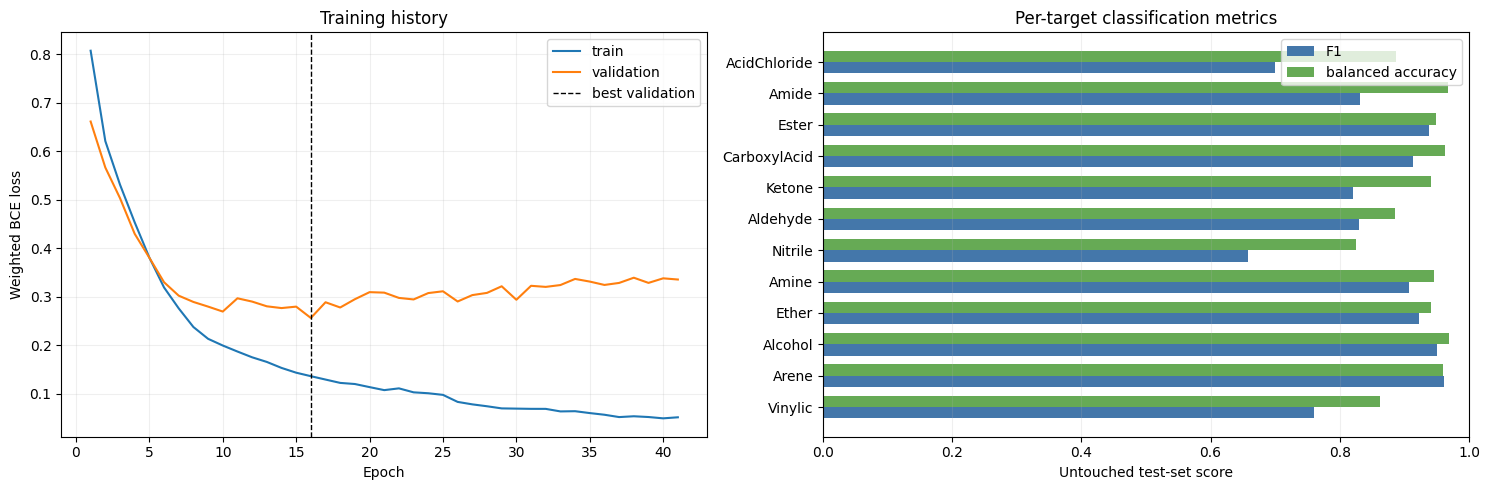

Saved model, metrics, predictions, plot, TensorBoard log, and documentation under outputs/optimized_training/run_20261013T135217842179Z.


In [4]:
def probabilities(features):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(features).to(DEVICE))).cpu().numpy()

validation_probability = probabilities(X_validation)
test_probability = probabilities(X_test)
threshold_grid = np.linspace(0.10, 0.90, 81)
thresholds = np.array([
    threshold_grid[np.argmax([f1_score(y_validation[:, index], validation_probability[:, index] >= threshold, zero_division=0)
                                  for threshold in threshold_grid])]
    for index in range(len(LABELS))
])
test_prediction = (test_probability >= thresholds).astype(int)
confusion = multilabel_confusion_matrix(y_test, test_prediction)
tn, fp, fn, tp = (confusion[:, 0, 0], confusion[:, 0, 1], confusion[:, 1, 0], confusion[:, 1, 1])
precision = tp / np.maximum(tp + fp, 1)
recall = tp / np.maximum(tp + fn, 1)
specificity = tn / np.maximum(tn + fp, 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
accuracy = (tp + tn) / np.maximum(tp + tn + fp + fn, 1)
balanced_accuracy = (recall + specificity) / 2
summary = pd.DataFrame({
    'label': LABELS, 'validation_threshold': thresholds, 'test_support': y_test.sum(axis=0),
    'true_negative': tn, 'false_positive': fp, 'false_negative': fn, 'true_positive': tp,
    'test_precision': precision, 'test_recall': recall, 'test_specificity': specificity,
    'test_F1': f1, 'test_accuracy': accuracy, 'test_balanced_accuracy': balanced_accuracy,
})
macro_f1 = f1_score(y_test, test_prediction, average='macro', zero_division=0)
micro_f1 = f1_score(y_test, test_prediction, average='micro', zero_division=0)
subset_accuracy = float(np.mean(np.all(y_test == test_prediction, axis=1)))
display(summary.round(3))
print(f'Untouched test metrics — macro F1: {macro_f1:.3f}; micro F1: {micro_f1:.3f}; exact-match accuracy: {subset_accuracy:.3f}')

summary.to_csv(RUN_DIR / 'test_metrics_by_label.csv', index=False)
predictions = test_frame[['NIST_molecule', 'CAS_NO', 'Name', 'SMILES']].copy()
for index, label in enumerate(LABELS):
    predictions[f'{label}_actual'] = y_test[:, index]
    predictions[f'{label}_probability'] = test_probability[:, index]
    predictions[f'{label}_prediction'] = test_prediction[:, index]
predictions.to_parquet(RUN_DIR / 'test_predictions.parquet', index=False)

model_bundle = {**best_checkpoint, 'thresholds': thresholds.tolist(),
                'run_documentation': str(RUN_DOCUMENTATION), 'test_macro_f1': float(macro_f1)}
torch.save(model_bundle, RUN_DIR / 'ir_functional_group_classifier.pt')
run_documentation['results'] = {'best_epoch': int(best_checkpoint['epoch']), 'best_validation_loss': float(best_checkpoint['validation_loss']),
                                'test_macro_f1': float(macro_f1), 'test_micro_f1': float(micro_f1),
                                'test_exact_match_accuracy': subset_accuracy}
RUN_DOCUMENTATION.write_text(json.dumps(run_documentation, indent=2), encoding='utf-8')
writer.add_scalar('metrics/test_macro_f1', macro_f1, best_checkpoint['epoch'])
writer.add_scalar('metrics/test_micro_f1', micro_f1, best_checkpoint['epoch'])
writer.flush(); writer.close()

history_frame = pd.DataFrame(history, columns=['epoch', 'train loss', 'validation loss', 'learning rate'])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history_frame.epoch, history_frame['train loss'], label='train')
axes[0].plot(history_frame.epoch, history_frame['validation loss'], label='validation')
axes[0].axvline(best_checkpoint['epoch'], color='black', ls='--', lw=1, label='best validation')
axes[0].set(title='Training history', xlabel='Epoch', ylabel='Weighted BCE loss'); axes[0].legend(); axes[0].grid(alpha=0.2)
position = np.arange(len(LABELS))
axes[1].barh(position - 0.18, summary['test_F1'], height=0.36, label='F1', color='#4477AA')
axes[1].barh(position + 0.18, summary['test_balanced_accuracy'], height=0.36, label='balanced accuracy', color='#66AA55')
axes[1].set(yticks=position, yticklabels=LABELS, xlim=(0, 1), xlabel='Untouched test-set score', title='Per-target classification metrics')
axes[1].legend(); axes[1].grid(axis='x', alpha=0.2)
fig.tight_layout(); fig.savefig(RUN_DIR / 'model_summary.png', dpi=160, bbox_inches='tight'); plt.show()
print(f'Saved model, metrics, predictions, plot, TensorBoard log, and documentation under {RUN_DIR}.')


## Classify an uploaded IR spectrum

Use the upload control below after training. Upload either a CSV with one row per point and `wavenumber` plus `IR` columns, or a one-row Parquet file whose `wavenumber` and `IR` columns contain arrays. The spectrum must cover the full wavenumber range recorded in the carpentry manifest. The notebook regrids it to the training grid without extrapolating, then reports predicted functional groups and probabilities using the validation-selected thresholds.

A prediction is a model result, not structural proof. Inspect the spectrum and its probabilities, especially for rare labels or spectra collected with a different instrument/preprocessing protocol.


In [5]:
from io import BytesIO
import ipywidgets as widgets

def uploaded_arrays(table):
    columns = {str(column).casefold(): column for column in table.columns}
    if 'wavenumber' not in columns or 'ir' not in columns:
        raise ValueError('Uploaded data need columns named wavenumber and IR (case-insensitive).')
    grid_column, signal_column = columns['wavenumber'], columns['ir']
    first_grid, first_signal = table[grid_column].iloc[0], table[signal_column].iloc[0]
    if isinstance(first_grid, (list, tuple, np.ndarray)) and isinstance(first_signal, (list, tuple, np.ndarray)):
        grid, signal = np.asarray(first_grid, dtype=float), np.asarray(first_signal, dtype=float)
    else:
        grid, signal = table[grid_column].to_numpy(dtype=float), table[signal_column].to_numpy(dtype=float)
    if grid.ndim != 1 or signal.ndim != 1 or len(grid) != len(signal) or len(grid) < 2:
        raise ValueError('The uploaded IR and wavenumber arrays must be finite, one-dimensional, and equally long.')
    order = np.argsort(grid); grid, signal = grid[order], signal[order]
    grid, inverse = np.unique(grid, return_inverse=True)
    signal = np.bincount(inverse, weights=signal) / np.bincount(inverse)
    if not (np.isfinite(grid).all() and np.isfinite(signal).all()):
        raise ValueError('The uploaded spectrum contains non-finite values.')
    if grid.min() > TARGET_GRID.min() or grid.max() < TARGET_GRID.max():
        raise ValueError('The uploaded spectrum does not cover the full training wavenumber range; it will not be extrapolated.')
    return np.interp(TARGET_GRID, grid, signal).astype(np.float32)

upload = widgets.FileUpload(accept='.csv,.parquet', multiple=False, description='Upload IR')
upload_output = widgets.Output()

def classify_upload(change):
    if not upload.value:
        return
    uploaded = next(iter(upload.value))
    name, content = uploaded['name'], uploaded['content']
    with upload_output:
        upload_output.clear_output(wait=True)
        try:
            table = pd.read_parquet(BytesIO(content)) if name.lower().endswith('.parquet') else pd.read_csv(BytesIO(content))
            spectrum = uploaded_arrays(table)
            probability = probabilities(scaler.transform(spectrum.reshape(1, -1)).astype(np.float32))[0]
            result = pd.DataFrame({'functional group': LABELS, 'probability': probability, 'threshold': thresholds,
                                   'present': probability >= thresholds})
            display(result.sort_values('probability', ascending=False).round(3))
        except Exception as error:
            print(f'Could not classify {name}: {error}')

upload.observe(classify_upload, names='value')
display(widgets.VBox([widgets.HTML('<b>Upload an IR CSV or Parquet file</b>'), upload, upload_output]))


Each execution gets a timestamped folder under `outputs/optimized_training/`, so the model, scaler, thresholds, metrics, predictions, plot, checkpoints, TensorBoard events, and machine-readable run documentation remain connected to the carpentry artifact that produced them.
